# 7. Cost versus carbon

**Goal of this notebook:** measure what the network does to transport emissions, and whether putting a price on carbon would change where the centers go.

Shipping a parcel 1,500 km through a parcel network burns more fuel per kilogram than moving the same goods in a full truck. A fulfillment network replaces long parcel trips with full-truck trips to the center plus a short parcel trip at the end. So it should cut emissions as well as cost. This notebook checks how much, how sure that number is, and what a carbon price would do.

It uses the regional model of notebook 5, planned for one future in which demand is 1.5 times the study year. Notebook 5 showed that planning for this average future gives the same network as planning for many futures at once.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import network_model as nm
import stochastic_model as sm
from helpers import COLORS, RESULTS, save_figure, set_chart_style

set_chart_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

data = nm.prepare()
regions, _ = sm.aggregate(data)
states = sorted(set(regions.state))
future = pd.Series({s: 1.5 for s in states})


def site_list(built):
    return ", ".join(regions.site_names[j].split(",")[0].title() + (" (L)" if k == "large" else "") for j, k in built)

## Step 1. Emission factors

Emissions are counted as kilograms of CO2 per tonne of product per kilometer (a tonne-km), using straight-line distances, for the product's own weight:

| Leg | Factor (kg CO2 per tonne-km) | Basis |
|---|---|---|
| Parcel network (direct shipments and the last leg from a center) | 0.25 | Assumption. Parcels travel in vans and part-loaded trucks, often with detours through sorting hubs. |
| Full truck from seller to center | 0.10 | The GLEC Framework (the industry standard for logistics emissions) gives about 0.07 to 0.11 for articulated diesel trucks. |

The parcel factor is the less certain of the two, so Step 3 varies both.

In [2]:
print(f"Parcel network: {sm.PARCEL_KG_CO2_PER_TKM} kg per tonne-km, full truck: {sm.TRUCK_KG_CO2_PER_TKM} kg per tonne-km")
base = sm.operate(regions, [], future)
print(f"Everything shipped direct, demand x1.5: {base['baseline_co2_t']:,.1f} tonnes of CO2 a year")

Parcel network: 0.25 kg per tonne-km, full truck: 0.1 kg per tonne-km
Everything shipped direct, demand x1.5: 37.5 tonnes of CO2 a year


The totals are small because the dataset is a sample of Olist's orders, as with the R\$ amounts. The percentages are what carries over.

## Step 2. A carbon price

Add a price per tonne of CO2 to the cost of every route, re-solve, and see what changes. For scale: the EU's carbon market has traded at roughly €60 to €90 a tonne in recent years, which is about R\$350 to R\$550. The range below goes far beyond that on purpose.

In [3]:
rows = []
for price in [0, 500, 2_500, 10_000, 25_000, 50_000]:
    plan = sm.design(regions, pd.DataFrame([future]), carbon_price=price)
    result = sm.operate(regions, plan["sites"], future, carbon_price=price)
    rows.append({
        "carbon price (R$ per tonne)": price,
        "centers": len(plan["sites"]),
        "net saving (R$)": result["baseline_cost"] - result["cost"] - plan["fixed_cost"],
        "CO2 (tonnes)": result["co2_t"],
        "CO2 vs shipping direct (%)": 100 * (result["co2_t"] / result["baseline_co2_t"] - 1),
        "items through a center (%)": result["via_fc_pct"],
        "sites": site_list(plan["sites"]),
    })
carbon = pd.DataFrame(rows).set_index("carbon price (R$ per tonne)")
carbon

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


,centers,net saving (R$),CO2 (tonnes),CO2 vs shipping direct (%),items through a center (%),sites
carbon price (R$ per tonne),,,,,,
0,9,"208,701.47",23.70,-36.79,80.21,"Brasilia, Curitiba, Porto Alegre, Salvador, Os..."
500,9,"208,329.19",23.62,-37.01,79.76,"Brasilia, Curitiba, Porto Alegre, Salvador, Re..."
2500,10,"207,839.44",23.08,-38.44,81.78,"Brasilia, Curitiba, Porto Alegre, Salvador, Re..."
10000,10,"206,646.32",22.85,-39.05,83.03,"Sao Paulo (L), Brasilia, Curitiba, Porto Alegr..."
25000,15,"171,390.94",20.66,-44.89,97.97,"Sao Paulo (L), Rio De Janeiro, Brasilia, Curit..."
50000,18,"147,259.41",20.01,-46.64,99.43,"Sao Paulo (L), Rio De Janeiro, Belo Horizonte,..."


**What this shows.**

- **The cheapest network is already a low-carbon network.** With no carbon price at all, it cuts transport CO2 by about 37%. Saving money and saving carbon point the same way here, because both come from replacing long parcel trips with full trucks.
- **No realistic carbon price changes the decision.** Up to R\$10,000 a tonne, about twenty times the EU price, the network barely changes and the saving moves by about R\$2,000. Only at R\$25,000 a tonne does the model restructure the network, adding centers to push nearly every item through one, and then it gives up about R\$37,000 of saving to cut emissions by another 8 points.

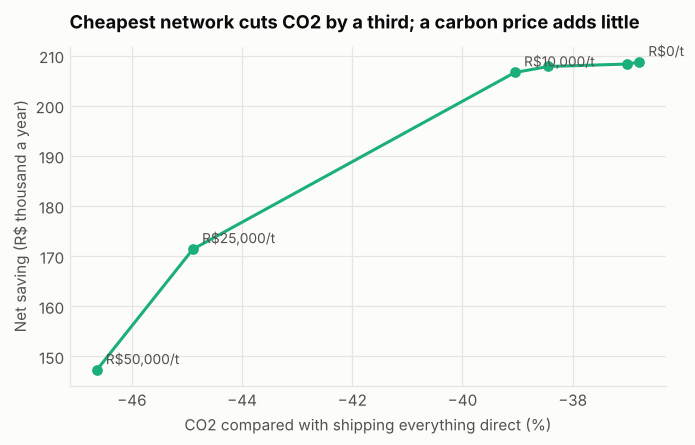

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(carbon["CO2 vs shipping direct (%)"], carbon["net saving (R$)"] / 1000, marker="o", color=COLORS["aqua"])
for price, row in carbon.iterrows():
    if price in (0, 10_000, 25_000, 50_000):
        ax.annotate(f"R${price:,}/t", (row["CO2 vs shipping direct (%)"], row["net saving (R$)"] / 1000),
                    textcoords="offset points", xytext=(6, 4), fontsize=9, color=COLORS["muted"])
ax.set_xlabel("CO2 compared with shipping everything direct (%)")
ax.set_ylabel("Net saving (R$ thousand a year)")
ax.set_title("Cheapest network cuts CO2 by a third; a carbon price adds little")
save_figure(fig, "07_cost_vs_carbon.png")
plt.show()

## Step 3. How sure is the 37%?

Keep the base network and its routing (which depend only on cost), and recount its emissions with other factors.

In [5]:
plan = sm.design(regions, pd.DataFrame([future]))
shares = sm.route_shares(regions, plan["sites"], future)     # share of each region sent through each site
mult = np.array([future[s] for s in regions.state])
direct_share = 1 - shares.sum(axis=1)
grid = pd.DataFrame(index=pd.Index([0.15, 0.25, 0.40, 0.60], name="parcel factor"),
                    columns=pd.Index([0.07, 0.10, 0.15], name="truck factor"), dtype=float)
for parcel in grid.index:
    for truck in grid.columns:
        network = (mult[:, None] * shares * regions.fc_co2(parcel, truck)).sum() \
            + (mult * direct_share * regions.direct_co2(parcel)).sum()
        today = (mult * regions.direct_co2(parcel)).sum()
        grid.loc[parcel, truck] = 100 * (1 - network / today)
print("Cut in transport CO2 (%), by emission factor:")
grid.round(0)

Cut in transport CO2 (%), by emission factor:


truck factor,0.07,0.10,0.15
parcel factor,,,
0.15,32.00,17.00,-9.00
0.25,46.00,37.00,22.00
0.40,54.00,48.00,39.00
0.60,58.00,55.00,48.00


**What this shows.** The size of the cut depends on how much dirtier a parcel network is than a full truck, per tonne-km. If parcels emit about two and a half times as much (0.25 against 0.10, the base case), the cut is about 37%. If the gap is bigger, as van-based delivery suggests, the cut passes 50%. If parcel networks were barely dirtier than trucks (0.15 against 0.15), the network would add emissions, because goods travel a little farther in total when they go through a center.

So the honest claim is: **the network cuts transport emissions as long as parcel delivery emits clearly more per tonne-km than a full truck, which published factors suggest it does, and the base case puts the cut at about a third.**

## What this notebook adds

- The cost-optimal network also cuts transport CO2 by about 37% in the base case.
- Cost and carbon point the same way. A carbon price would have to be about fifty times the EU's before it changed the design in a meaningful way.
- The size of the cut depends on emission factors that should be measured with real carriers. The direction holds across the plausible range.

In [6]:
carbon.to_csv(RESULTS / "carbon_price.csv")
grid.to_csv(RESULTS / "carbon_factor_sensitivity.csv")
print("Saved results/carbon_*.csv")

Saved results/carbon_*.csv
